In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
np.random.seed(42)

total_students = 300

branches = [
    "Computer Science",
    "Electrical Engineering",
    "Mechanical Engineering",
    "Civil Engineering",
    "Chemical Engineering",
    "Aerospace Engineering",
    "Mathematics",
    "Metallurgy"
]

branch_prob = [0.15, 0.18, 0.16, 0.10, 0.10, 0.08, 0.13, 0.10]

branch = np.random.choice(
    branches,
    total_students,
    p=branch_prob
)

cgpa = np.round(np.random.uniform(6.0, 10.0, total_students), 2)

coding_score = np.random.randint(30, 101, total_students)

print("Dataset variables created")

Dataset variables created


In [3]:
branch_probability = {
    "Computer Science": 0.90,
    "Electrical Engineering": 0.82,
    "Mechanical Engineering": 0.72,
    "Civil Engineering": 0.65,
    "Chemical Engineering": 0.75,
    "Aerospace Engineering": 0.78,
    "Mathematics": 0.85,
    "Metallurgy": 0.68
}

probability = np.array([
    branch_probability[b] + (gpa - 8) * 0.03
    for b, gpa in zip(branch, cgpa)
])

probability = np.clip(probability, 0.35, 0.98)

placed = np.random.binomial(1, probability)

placement_status = np.where(
    placed == 1,
    "Placed",
    "Not Placed"
)

print("Placement status generated")

Placement status generated


In [4]:
companies = [
    "Google",
    "Microsoft",
    "Amazon",
    "Goldman Sachs",
    "TCS",
    "Accenture",
    "Qualcomm",
    "Flipkart",
    "Deloitte",
    "NVIDIA",
    "Samsung",
    "Reliance"
]

sectors = {
    "Google": "Software & IT",
    "Microsoft": "Software & IT",
    "Amazon": "Software & IT",
    "Goldman Sachs": "Finance",
    "TCS": "Software & IT",
    "Accenture": "Consulting",
    "Qualcomm": "Electronics",
    "Flipkart": "E-Commerce",
    "Deloitte": "Consulting",
    "NVIDIA": "Electronics",
    "Samsung": "Electronics",
    "Reliance": "Core & Business"
}

company = np.random.choice(companies, total_students)

base_salary = np.where(
    placed == 1,
    np.round(np.random.uniform(6, 35, total_students), 2),
    np.nan
)

total_ctc = np.where(
    placed == 1,
    np.round(base_salary + np.random.uniform(1, 15, total_students), 2),
    np.nan
)

sector = [sectors[c] for c in company]

offers = np.where(
    placed == 1,
    np.random.randint(1, 4, total_students),
    0
)

print("Company and salary data generated")

Company and salary data generated


In [5]:
df = pd.DataFrame({
    "Student_ID": range(1001, 1001 + total_students),
    "Institute": "IIT Bombay",
    "Branch": branch,
    "CGPA": cgpa,
    "Coding_Score": coding_score,
    "Placement_Status": placement_status,
    "Company": np.where(placed == 1, company, "None"),
    "Sector": np.where(placed == 1, sector, "None"),
    "Offers": offers,
    "Base_Salary_LPA": base_salary,
    "Total_CTC_LPA": total_ctc
})

df.head(10)

,Student_ID,Institute,Branch,CGPA,Coding_Score,Placement_Status,Company,Sector,Offers,Base_Salary_LPA,Total_CTC_LPA
0,1001,IIT Bombay,Mechanical Engineering,6.21,34,Placed,Accenture,Consulting,3,16.42,29.65
1,1002,IIT Bombay,Metallurgy,8.13,71,Placed,Reliance,Core & Business,2,17.13,20.39
2,1003,IIT Bombay,Aerospace Engineering,8.16,90,Placed,Qualcomm,Electronics,3,19.51,31.52
3,1004,IIT Bombay,Chemical Engineering,8.55,51,Placed,TCS,Software & IT,2,30.24,39.28
4,1005,IIT Bombay,Electrical Engineering,8.90,50,Placed,Samsung,Electronics,3,12.84,21.77
5,1006,IIT Bombay,Electrical Engineering,9.90,99,Placed,NVIDIA,Electronics,3,28.50,34.97
6,1007,IIT Bombay,Computer Science,8.07,30,Placed,Deloitte,Consulting,1,17.75,25.77
7,1008,IIT Bombay,Mathematics,7.29,34,Placed,Amazon,Software & IT,2,23.45,30.01
8,1009,IIT Bombay,Chemical Engineering,9.18,41,Placed,Qualcomm,Electronics,1,24.34,32.90
9,1010,IIT Bombay,Aerospace Engineering,7.08,75,Placed,NVIDIA,Electronics,1,16.81,26.60


In [6]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (300, 11)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        300 non-null    int64  
 1   Institute         300 non-null    str    
 2   Branch            300 non-null    str    
 3   CGPA              300 non-null    float64
 4   Coding_Score      300 non-null    int32  
 5   Placement_Status  300 non-null    str    
 6   Company           300 non-null    str    
 7   Sector            300 non-null    str    
 8   Offers            300 non-null    int32  
 9   Base_Salary_LPA   238 non-null    float64
 10  Total_CTC_LPA     238 non-null    float64
dtypes: float64(3), int32(2), int64(1), str(5)
memory usage: 38.6 KB

Missing Values:
Student_ID           0
Institute            0
Branch               0
CGPA                 0
Coding_Score         0
Placement_Status     0
Company              0
S

,Student_ID,CGPA,Coding_Score,Offers,Base_Salary_LPA,Total_CTC_LPA
count,300.000000,300.000000,300.000000,300.000000,238.000000,238.000000
mean,1150.500000,8.043033,64.353333,1.566667,20.150000,27.715210
std,86.746758,1.210334,20.694347,1.072095,7.867791,8.492673
min,1001.000000,6.040000,30.000000,0.000000,6.040000,10.170000
25%,1075.750000,6.997500,46.000000,1.000000,13.450000,20.990000
50%,1150.500000,8.085000,65.000000,2.000000,19.380000,27.650000
75%,1225.250000,9.095000,81.250000,2.000000,26.275000,34.237500
max,1300.000000,10.000000,100.000000,3.000000,34.870000,47.160000


In [7]:
total = len(df)

placed_students = (df["Placement_Status"] == "Placed").sum()

placement_rate = (placed_students / total) * 100

avg_ctc = df["Total_CTC_LPA"].mean()

median_ctc = df["Total_CTC_LPA"].median()

highest_ctc = df["Total_CTC_LPA"].max()

avg_base = df["Base_Salary_LPA"].mean()

avg_cgpa = df["CGPA"].mean()

total_offers = df["Offers"].sum()

print("===== IIT BOMBAY PLACEMENT DASHBOARD =====")
print("Total Students:", total)
print("Placed Students:", placed_students)
print("Placement Rate:", round(placement_rate, 2), "%")
print("Average CTC:", round(avg_ctc, 2), "LPA")
print("Median CTC:", round(median_ctc, 2), "LPA")
print("Highest CTC:", round(highest_ctc, 2), "LPA")
print("Average Base Salary:", round(avg_base, 2), "LPA")
print("Average CGPA:", round(avg_cgpa, 2))
print("Total Offers:", total_offers)

===== IIT BOMBAY PLACEMENT DASHBOARD =====
Total Students: 300
Placed Students: 238
Placement Rate: 79.33 %
Average CTC: 27.72 LPA
Median CTC: 27.65 LPA
Highest CTC: 47.16 LPA
Average Base Salary: 20.15 LPA
Average CGPA: 8.04
Total Offers: 470


In [8]:
branch_summary = df.groupby("Branch").agg(
    Total_Students=("Student_ID", "count"),
    Placed_Students=("Placement_Status",
                     lambda x: (x == "Placed").sum()),
    Avg_CGPA=("CGPA", "mean"),
    Avg_Coding=("Coding_Score", "mean"),
    Avg_Base_Salary=("Base_Salary_LPA", "mean"),
    Avg_CTC=("Total_CTC_LPA", "mean"),
    Highest_CTC=("Total_CTC_LPA", "max")
)

branch_summary["Placement_Rate"] = (
    branch_summary["Placed_Students"] /
    branch_summary["Total_Students"] * 100
)

branch_summary = branch_summary.round(2)

branch_summary

,Total_Students,Placed_Students,Avg_CGPA,Avg_Coding,Avg_Base_Salary,Avg_CTC,Highest_CTC,Placement_Rate
Branch,,,,,,,,
Aerospace Engineering,23,16,7.60,68.17,18.44,26.93,47.16,69.57
Chemical Engineering,33,28,8.34,67.27,20.87,27.60,43.53,84.85
Civil Engineering,32,18,8.14,64.28,24.47,31.59,45.22,56.25
Computer Science,48,41,7.99,67.31,18.00,25.86,40.03,85.42
Electrical Engineering,60,53,8.33,61.37,20.48,28.63,45.58,88.33
Mathematics,43,36,7.97,60.81,18.61,25.63,43.74,83.72
Mechanical Engineering,32,23,7.95,63.25,20.48,27.28,41.25,71.88
Metallurgy,29,23,7.64,65.83,22.25,30.26,41.61,79.31


In [9]:
best_branch = branch_summary["Placement_Rate"].idxmax()

print("Best Placement Branch:", best_branch)

print("Placement Rate:",
      branch_summary.loc[best_branch, "Placement_Rate"], "%")

Best Placement Branch: Electrical Engineering
Placement Rate: 88.33 %


In [10]:
highest_branch = branch_summary["Highest_CTC"].idxmax()

print("Highest Package Branch:", highest_branch)

print("Highest Package:",
      branch_summary.loc[highest_branch, "Highest_CTC"],
      "LPA")

Highest Package Branch: Aerospace Engineering
Highest Package: 47.16 LPA


In [11]:
company_summary = df[df["Placement_Status"] == "Placed"].groupby("Company").agg(
    Students_Selected=("Student_ID", "count"),
    Average_CTC=("Total_CTC_LPA", "mean"),
    Highest_CTC=("Total_CTC_LPA", "max"),
    Average_Base=("Base_Salary_LPA", "mean")
)

company_summary = company_summary.sort_values(
    "Students_Selected",
    ascending=False
)

company_summary = company_summary.round(2)

company_summary

,Students_Selected,Average_CTC,Highest_CTC,Average_Base
Company,,,,
Reliance,29,27.23,43.06,21.11
Microsoft,25,27.92,47.16,20.24
Goldman Sachs,22,25.45,39.36,19.56
Accenture,21,28.60,42.62,21.11
Samsung,21,28.34,43.53,20.75
Google,20,25.41,45.22,17.19
Amazon,19,29.38,39.86,21.95
Qualcomm,18,28.27,37.64,20.04
Flipkart,17,27.89,41.61,19.45


In [12]:
top_companies = company_summary.head(10)

top_companies

,Students_Selected,Average_CTC,Highest_CTC,Average_Base
Company,,,,
Reliance,29,27.23,43.06,21.11
Microsoft,25,27.92,47.16,20.24
Goldman Sachs,22,25.45,39.36,19.56
Accenture,21,28.60,42.62,21.11
Samsung,21,28.34,43.53,20.75
Google,20,25.41,45.22,17.19
Amazon,19,29.38,39.86,21.95
Qualcomm,18,28.27,37.64,20.04
Flipkart,17,27.89,41.61,19.45


In [13]:
sector_summary = df[df["Placement_Status"] == "Placed"].groupby("Sector").agg(
    Students_Placed=("Student_ID", "count"),
    Average_CTC=("Total_CTC_LPA", "mean"),
    Highest_CTC=("Total_CTC_LPA", "max")
)

sector_summary = sector_summary.sort_values(
    "Students_Placed",
    ascending=False
)

sector_summary.round(2)

,Students_Placed,Average_CTC,Highest_CTC
Sector,,,
Software & IT,76,27.06,47.16
Electronics,56,28.30,43.53
Consulting,38,29.76,45.15
Core & Business,29,27.23,43.06
Finance,22,25.45,39.36
E-Commerce,17,27.89,41.61


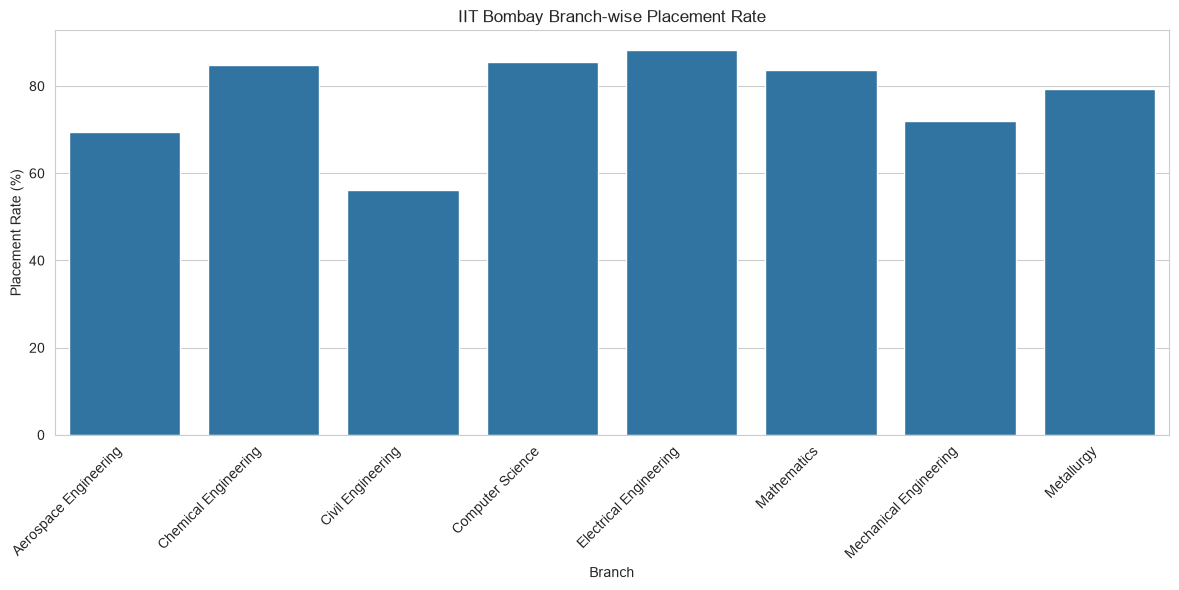

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=branch_summary.index,
    y=branch_summary["Placement_Rate"]
)

plt.title("IIT Bombay Branch-wise Placement Rate")
plt.xlabel("Branch")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

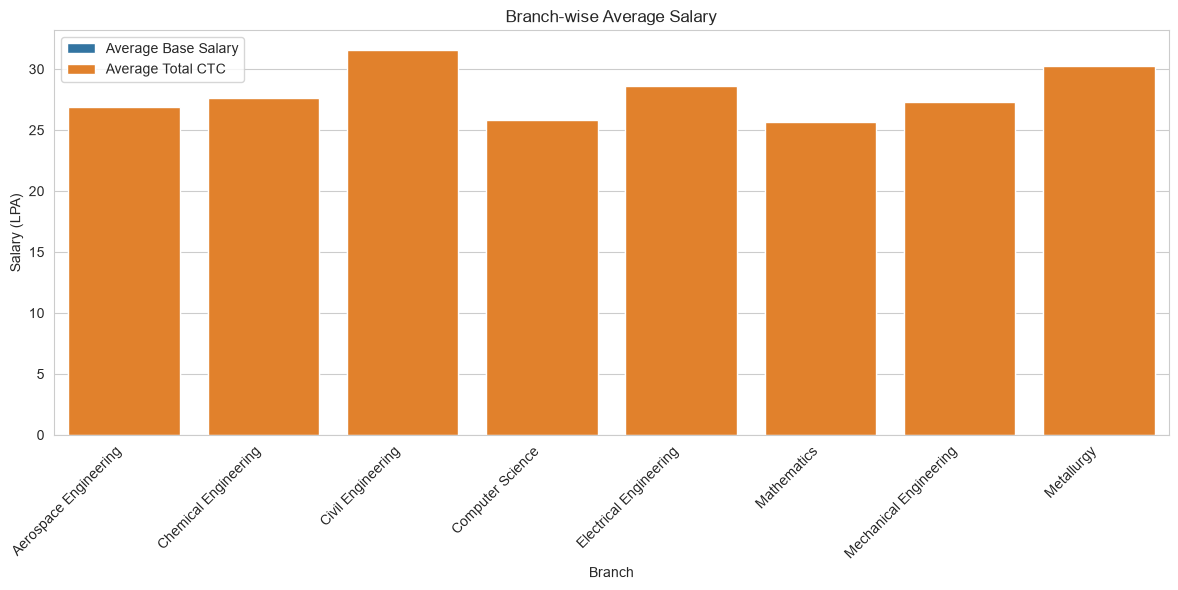

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=branch_summary,
    x=branch_summary.index,
    y="Avg_Base_Salary",
    label="Average Base Salary"
)

sns.barplot(
    data=branch_summary,
    x=branch_summary.index,
    y="Avg_CTC",
    label="Average Total CTC"
)

plt.title("Branch-wise Average Salary")
plt.xlabel("Branch")
plt.ylabel("Salary (LPA)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

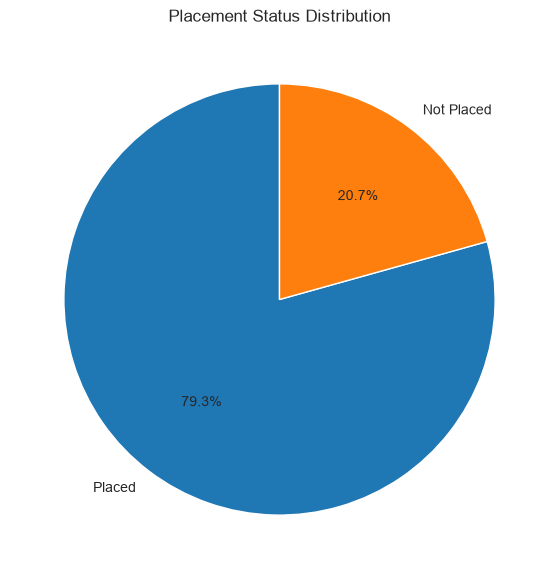

In [16]:
placement_count = df["Placement_Status"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    placement_count,
    labels=placement_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Placement Status Distribution")
plt.show()

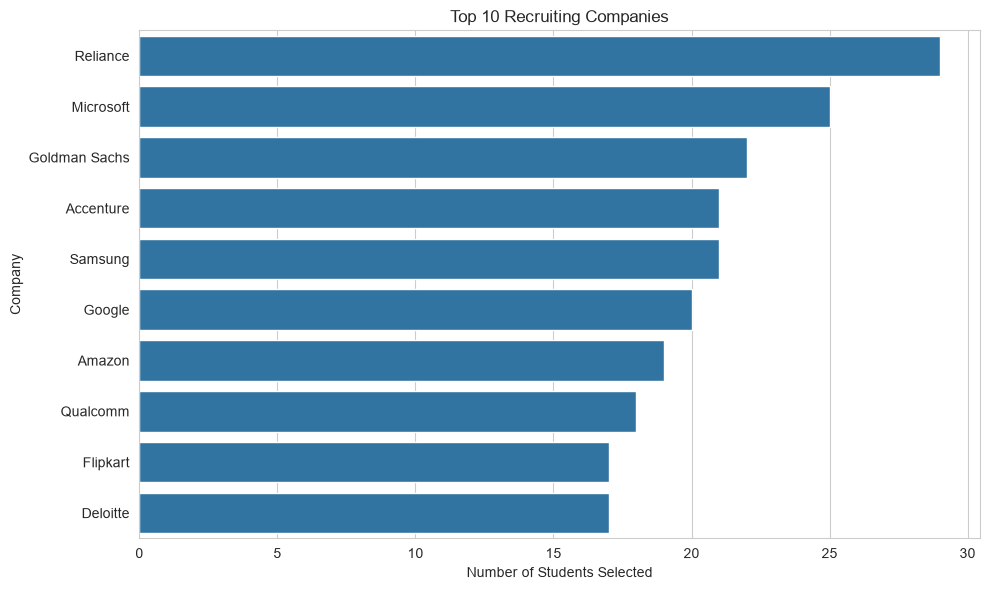

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_companies["Students_Selected"],
    y=top_companies.index
)

plt.title("Top 10 Recruiting Companies")
plt.xlabel("Number of Students Selected")
plt.ylabel("Company")
plt.tight_layout()
plt.show()

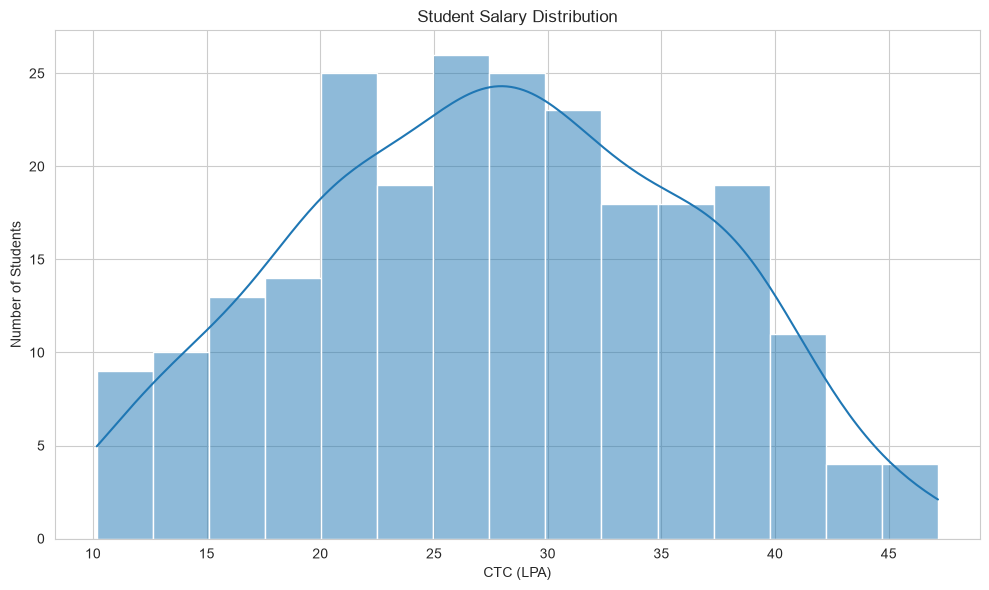

In [18]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Total_CTC_LPA"].dropna(),
    bins=15,
    kde=True
)

plt.title("Student Salary Distribution")
plt.xlabel("CTC (LPA)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

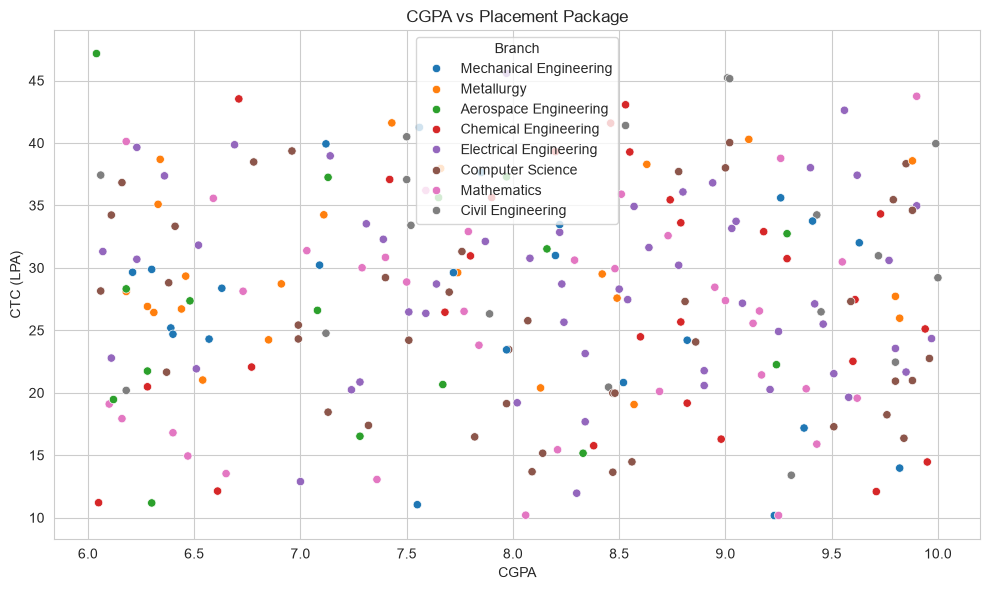

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df[df["Placement_Status"] == "Placed"],
    x="CGPA",
    y="Total_CTC_LPA",
    hue="Branch"
)

plt.title("CGPA vs Placement Package")
plt.xlabel("CGPA")
plt.ylabel("CTC (LPA)")
plt.tight_layout()
plt.show()

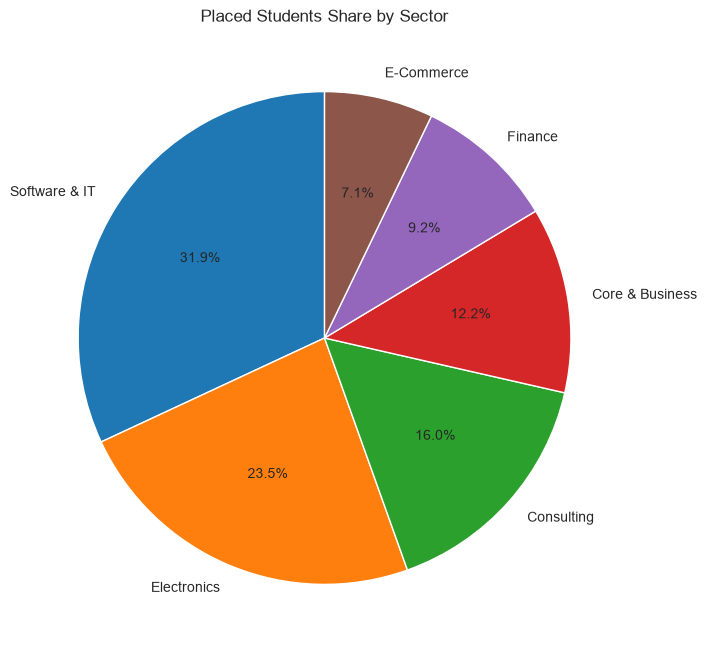

In [20]:
plt.figure(figsize=(8, 8))

plt.pie(
    sector_summary["Students_Placed"],
    labels=sector_summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Placed Students Share by Sector")
plt.show()

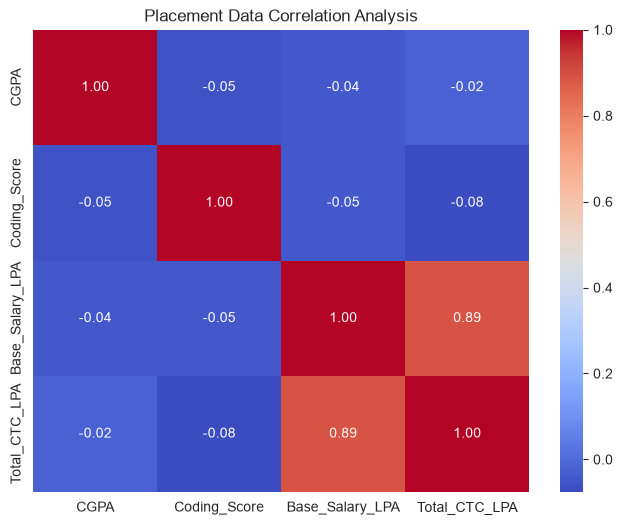

In [21]:
correlation = df[
    ["CGPA", "Coding_Score", "Base_Salary_LPA", "Total_CTC_LPA"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Placement Data Correlation Analysis")
plt.show()

In [22]:
print("========== FINAL PLACEMENT REPORT ==========")

print("Institute: IIT Bombay")
print("Batch Size:", total)
print("Placed Students:", placed_students)

print("Overall Placement Rate:",
      round(placement_rate, 2), "%")

print("Average Package:",
      round(avg_ctc, 2), "LPA")

print("Median Package:",
      round(median_ctc, 2), "LPA")

print("Highest Package:",
      round(highest_ctc, 2), "LPA")

print("Average Base Salary:",
      round(avg_base, 2), "LPA")

print("Best Branch:",
      best_branch)

print("Total Offers:",
      total_offers)

print("========================================")

========== FINAL PLACEMENT REPORT ==========
Institute: IIT Bombay
Batch Size: 300
Placed Students: 238
Overall Placement Rate: 79.33 %
Average Package: 27.72 LPA
Median Package: 27.65 LPA
Highest Package: 47.16 LPA
Average Base Salary: 20.15 LPA
Best Branch: Electrical Engineering
Total Offers: 470


In [23]:
df.to_csv("IIT_Bombay_Placement_Data.csv", index=False)

branch_summary.to_csv("Branch_Placement_Analysis.csv")

company_summary.to_csv("Company_Placement_Analysis.csv")

sector_summary.to_csv("Sector_Placement_Analysis.csv")

print("All CSV files saved successfully")

All CSV files saved successfully
